In [1]:
# ---------- CELL 0: locate the project (same in every notebook) ----------
import os, sys
from pathlib import Path

def find_root(marker="PROJECT_ROOT.marker"):
    here = Path.cwd().resolve()                      # start where this notebook runs
    for folder in [here, *here.parents]:             # go UP one level at a time
        if (folder / marker).exists():
            return folder
    if "google.colab" in sys.modules:                # Colab: look inside Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        for pattern in (marker, f"*/{marker}", f"*/*/{marker}", f"*/*/*/{marker}"):
            hits = sorted(Path("/content/drive/MyDrive").glob(pattern))
            if hits:
                return hits[0].parent
    raise FileNotFoundError("PROJECT_ROOT.marker not found - finish Day 1 first.")

ROOT = find_root()
os.chdir(ROOT / "notebooks")
RAW, CLEAN = ROOT/"data"/"raw", ROOT/"data"/"clean"
FEATURES, MODEL_OUT = ROOT/"data"/"features", ROOT/"data"/"model_outputs"
SQL_EXPORTS, BI_READY = ROOT/"data"/"sql_exports", ROOT/"data"/"bi_ready"
MODELS, REPORTS, DOCS = ROOT/"models", ROOT/"reports", ROOT/"docs"
FIGURES = REPORTS/"figures"
sys.path.append(str(ROOT/"src"))
print("Project root:", ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root: /content/drive/MyDrive/Internmo/netflix_churn_project


In [2]:
# ---------- CELL 1: load active customers and add the value features ----------
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

features = pd.read_csv(FEATURES / "customer_features_scoring.csv")
active = features[features["active_at_snapshot"]].copy()

payments = pd.read_csv(CLEAN / "payments.csv", usecols=["customer_id", "payment_status", "amount"])
plans = pd.read_csv(CLEAN / "subscription_plans.csv").set_index("plan_name")["monthly_price"]

lifetime_spend = (payments[payments["payment_status"] == "Success"]
                  .groupby("customer_id")["amount"].sum().rename("lifetime_spend"))
active = active.merge(lifetime_spend, on="customer_id", how="left")
active["lifetime_spend"] = active["lifetime_spend"].fillna(0)
active["plan_price"] = active["plan_name"].map(plans)

SEGMENT_FEATURES = ["days_since_last_view", "sessions_90d", "minutes_90d", "avg_completion_90d",
                    "lifetime_spend", "plan_price", "tenure_days", "tickets_365d", "failed_payments_12m"]
print(len(active), "active customers | blanks per feature:")
print(active[SEGMENT_FEATURES].isna().sum()[lambda s: s > 0])

6009 active customers | blanks per feature:
avg_completion_90d    961
dtype: int64


In [3]:
# ---------- CELL 2: transform and scale ----------
from sklearn.preprocessing import StandardScaler

LOG_FEATURES = ["sessions_90d", "minutes_90d", "lifetime_spend", "tickets_365d", "failed_payments_12m"]
COMPLETION_MEDIAN = active["avg_completion_90d"].median()          # customers with no sessions have no completion

def prepare(df):
    """Same preparation for training and for scoring new customers later."""
    X = df[SEGMENT_FEATURES].copy()
    X["avg_completion_90d"] = X["avg_completion_90d"].fillna(COMPLETION_MEDIAN)
    X[LOG_FEATURES] = np.log1p(X[LOG_FEATURES])
    return X

scaler = StandardScaler()
Z = scaler.fit_transform(prepare(active))
print("scaled matrix:", Z.shape, "| column means ~0:", np.round(Z.mean(axis=0)[:3], 2))

scaled matrix: (6009, 9) | column means ~0: [ 0.  0. -0.]


   k    inertia  silhouette
0  2  42218.897       0.265
1  3  35145.501       0.230
2  4  29985.628       0.252
3  5  26961.706       0.249
4  6  24985.671       0.245
5  7  23056.501       0.257
6  8  21646.876       0.240


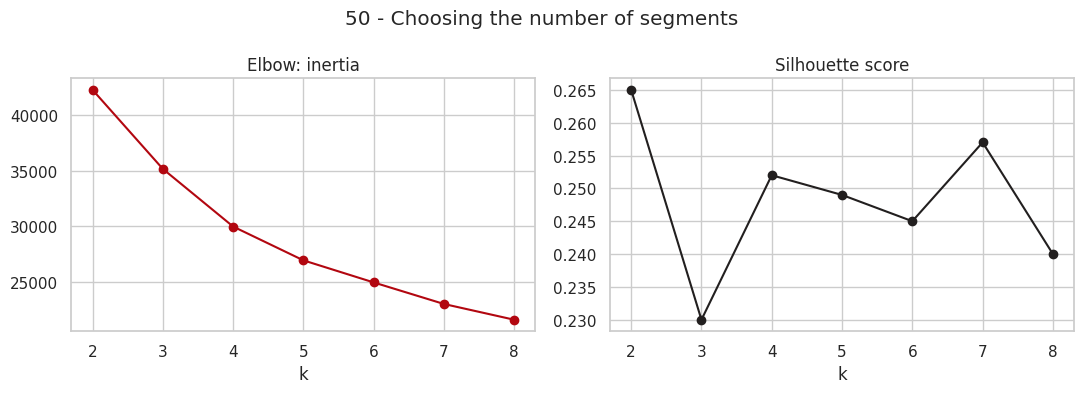

In [4]:
# ---------- CELL 3: elbow and silhouette ----------
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    results.append({"k": k, "inertia": km.inertia_,
                    "silhouette": silhouette_score(Z, km.labels_, sample_size=3000, random_state=42)})
k_table = pd.DataFrame(results).round(3)
print(k_table)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_table["k"], k_table["inertia"], marker="o", color="#b20710"); axes[0].set_title("Elbow: inertia"); axes[0].set_xlabel("k")
axes[1].plot(k_table["k"], k_table["silhouette"], marker="o", color="#221f1f"); axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k")
fig.suptitle("50 - Choosing the number of segments")
plt.tight_layout(); plt.savefig(FIGURES / "50_choose_k.png", bbox_inches="tight"); plt.show()

In [5]:
# ---------- CELL 4: final model and stability test ----------
from sklearn.metrics import adjusted_rand_score

K = 5
final_km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Z)
active["segment_id"] = final_km.labels_

# Stability: refit with 5 different random starts. ARI = 1 means identical grouping, 0 means unrelated.
ari = [adjusted_rand_score(final_km.labels_, KMeans(n_clusters=K, n_init=10, random_state=s).fit(Z).labels_) for s in range(1, 6)]
print("Stability (adjusted Rand index vs 5 other random starts):", np.round(ari, 2))
print("segment sizes:", active["segment_id"].value_counts().sort_index().to_dict())

Stability (adjusted Rand index vs 5 other random starts): [1. 1. 1. 1. 1.]
segment sizes: {0: 455, 1: 1520, 2: 2283, 3: 989, 4: 762}


            customers  days_since_last_view  sessions_90d  minutes_90d  avg_completion_90d  lifetime_spend  plan_price  tenure_days  tickets_365d  failed_payments_12m
segment_id                                                                                                                                                            
0                 455                  32.1           3.1        150.2                70.3           125.9        12.5        410.5           0.7                  1.3
1                1520                  25.3           3.2        156.2                70.6            97.3         7.0       1720.0           0.0                  0.0
2                2283                  24.3           3.3        163.2                70.9           260.1        18.4       1647.5           0.1                  0.0
3                 989                  88.8           0.1          1.8                75.2           194.7        14.2       1503.8           0.2                  0.

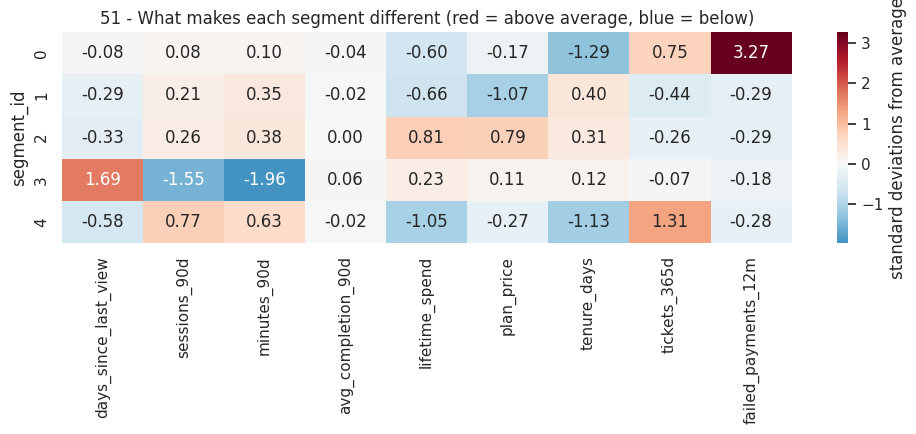

In [6]:
# ---------- CELL 5: segment profile ----------
profile = active.groupby("segment_id")[SEGMENT_FEATURES].mean().round(1)
profile.insert(0, "customers", active["segment_id"].value_counts().sort_index())
print(profile.to_string())

# the same, expressed as "how far above or below the all-customer average" (z-score)
Z_df = pd.DataFrame(Z, columns=SEGMENT_FEATURES)
Z_df["segment_id"] = active["segment_id"].values
z_profile = Z_df.groupby("segment_id").mean().round(2)

plt.figure(figsize=(10, 4.5))
sns.heatmap(z_profile, annot=True, cmap="RdBu_r", center=0, fmt=".2f", cbar_kws={"label": "standard deviations from average"})
plt.title("51 - What makes each segment different (red = above average, blue = below)")
plt.tight_layout(); plt.savefig(FIGURES / "51_segment_profile_heatmap.png", bbox_inches="tight"); plt.show()

In [7]:
# ---------- CELL 6: name the segments ----------
def name_segment(z):
    """z = one row of the z-score table (one segment)."""
    if z["failed_payments_12m"] > 1:                              return "Payment Trouble"
    if z["days_since_last_view"] > 1:                             return "Dormant"
    if z["sessions_90d"] > 0.5 and z["tenure_days"] < -0.5:       return "New & Highly Engaged"
    if z["lifetime_spend"] > 0.5:                                 return "High-Value Loyalists"
    if z["plan_price"] < -0.5:                                    return "Budget Regulars"
    return "Steady Viewers"

names = {seg: name_segment(row) for seg, row in z_profile.iterrows()}

# if two segments got the same name, add a number so the names stay unique
seen = {}
for seg in sorted(names):
    n = names[seg]
    seen[n] = seen.get(n, 0) + 1
    if list(names.values()).count(n) > 1:
        names[seg] = f"{n} {seen[n]}"
active["segment_name"] = active["segment_id"].map(names)
print(names)

{0: 'Payment Trouble', 1: 'Budget Regulars', 2: 'High-Value Loyalists', 3: 'Dormant', 4: 'New & Highly Engaged'}


In [8]:
# ---------- CELL 7: attach the Day 10 predictions ----------
predictions = pd.read_csv(MODEL_OUT / "churn_predictions.csv")[["customer_id", "churn_probability", "risk_tier"]]
active = active.merge(predictions, on="customer_id", how="left")
assert active["churn_probability"].notna().all(), "predictions missing for some active customers"

# expected monthly revenue at risk = probability of churning x what they pay each month
active["expected_revenue_at_risk"] = (active["churn_probability"] * active["plan_price"]).round(2)

segment_profile = (active.groupby(["segment_id", "segment_name"])
    .agg(customers=("customer_id", "count"),
         avg_days_since_last_view=("days_since_last_view", "mean"),
         avg_sessions_90d=("sessions_90d", "mean"),
         avg_lifetime_spend=("lifetime_spend", "mean"),
         avg_plan_price=("plan_price", "mean"),
         avg_tenure_days=("tenure_days", "mean"),
         avg_tickets_365d=("tickets_365d", "mean"),
         avg_failed_payments_12m=("failed_payments_12m", "mean"),
         avg_churn_probability=("churn_probability", "mean"),
         high_risk_customers=("risk_tier", lambda s: (s == "High").sum()),
         monthly_revenue=("plan_price", "sum"),
         expected_revenue_at_risk=("expected_revenue_at_risk", "sum"))
    .reset_index())
segment_profile["pct_high_risk"] = (100 * segment_profile["high_risk_customers"] / segment_profile["customers"]).round(1)
segment_profile = segment_profile.round(2).sort_values("expected_revenue_at_risk", ascending=False)
segment_profile

,segment_id,segment_name,customers,avg_days_since_last_view,avg_sessions_90d,avg_lifetime_spend,avg_plan_price,avg_tenure_days,avg_tickets_365d,avg_failed_payments_12m,avg_churn_probability,high_risk_customers,monthly_revenue,expected_revenue_at_risk,pct_high_risk
2,2,High-Value Loyalists,2283,24.26,3.32,260.05,18.37,1647.54,0.13,0.00,0.24,278,41933.67,9889.49,12.2
3,3,Dormant,989,88.81,0.09,194.70,14.20,1503.75,0.23,0.03,0.22,69,14040.61,3176.31,7.0
4,4,New & Highly Engaged,762,16.03,5.34,101.52,11.90,532.31,0.98,0.00,0.29,427,9070.88,2678.68,56.0
1,1,Budget Regulars,1520,25.26,3.17,97.26,6.99,1719.95,0.05,0.00,0.23,147,10624.80,2473.12,9.7
0,0,Payment Trouble,455,32.09,3.10,125.88,12.52,410.51,0.72,1.28,0.31,280,5694.95,1768.60,61.5


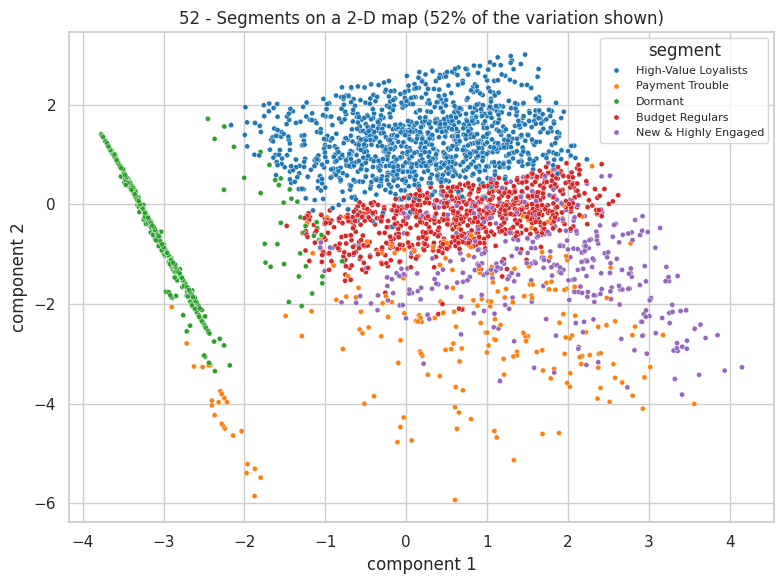

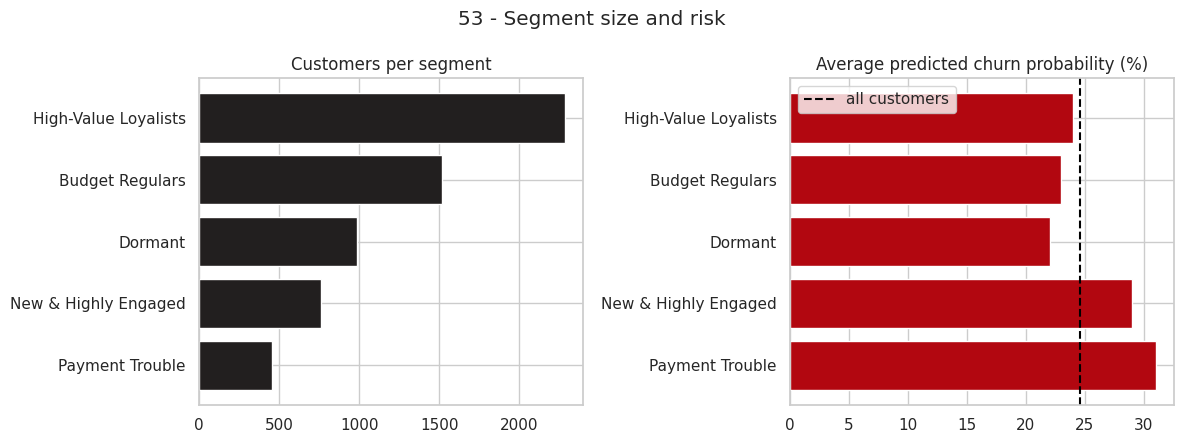

In [9]:
# ---------- CELL 8: 2-D map and size/risk chart ----------
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
points = pca.fit_transform(Z)
sample = np.random.RandomState(42).choice(len(points), size=min(3000, len(points)), replace=False)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=points[sample, 0], y=points[sample, 1], hue=active["segment_name"].values[sample], s=14, palette="tab10")
plt.title(f"52 - Segments on a 2-D map ({100 * pca.explained_variance_ratio_.sum():.0f}% of the variation shown)")
plt.xlabel("component 1"); plt.ylabel("component 2"); plt.legend(title="segment", fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES / "52_segments_2d.png", bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
order = segment_profile.sort_values("customers")
axes[0].barh(order["segment_name"], order["customers"], color="#221f1f"); axes[0].set_title("Customers per segment")
axes[1].barh(order["segment_name"], order["avg_churn_probability"] * 100, color="#b20710")
axes[1].axvline(100 * active["churn_probability"].mean(), color="black", linestyle="--", label="all customers")
axes[1].set_title("Average predicted churn probability (%)"); axes[1].legend()
fig.suptitle("53 - Segment size and risk")
plt.tight_layout(); plt.savefig(FIGURES / "53_segment_size_and_risk.png", bbox_inches="tight"); plt.show()

In [10]:
# ---------- CELL 9: save ----------
MODELS.mkdir(exist_ok=True)
joblib.dump({"scaler": scaler, "kmeans": final_km, "features": SEGMENT_FEATURES, "log_features": LOG_FEATURES,
             "completion_median": COMPLETION_MEDIAN, "names": names}, MODELS / "segment_model.joblib")

active[["customer_id", "segment_id", "segment_name", "churn_probability", "risk_tier",
        "plan_price", "lifetime_spend", "expected_revenue_at_risk"]].to_csv(MODEL_OUT / "customer_segments.csv", index=False)
segment_profile.to_csv(MODEL_OUT / "segment_profile.csv", index=False)

# checks: one row per active customer, every customer in exactly one segment
saved = pd.read_csv(MODEL_OUT / "customer_segments.csv")
assert saved["customer_id"].is_unique and len(saved) == len(active)
assert saved["segment_name"].notna().all()
print("saved", len(saved), "customers in", saved["segment_name"].nunique(), "segments")

with open(DOCS / "project_log.md", "a") as f:
    f.write(f"""## Day 11 - Segmentation
- K-Means with k={K} on 9 behaviour/value features (log + standard scaling). Silhouette about {k_table.loc[k_table.k == K, 'silhouette'].iloc[0]} (weak separation, k chosen for business usefulness).
- Stability (ARI vs other seeds): {np.round(np.mean(ari), 2)} on average.
- Segments: {', '.join(sorted(set(names.values())))}.
- Saved models/segment_model.joblib, data/model_outputs/customer_segments.csv, segment_profile.csv.

""")

saved 6009 customers in 5 segments
